# Klustring av amerikanska aktier

## 1. Problem och syfte

Investerare som vill sprida sin risk väljer ofta aktier från olika sektorer. Men aktier från olika sektorer kan ändå bete sig likt, till exempel röra sig lika mycket när marknaden svänger eller ha liknande lönsamhet och skuldsättning.

**Syfte:** gruppera cirka 2 000 amerikanska aktier efter bolagens räkenskaper och aktiernas kursbeteende, och undersöka om grupperna följer sektorindelningen eller om det finns några andra mönster.

**Varför maskininlärning?** Med tusentals aktier och ett tiotal variabler per aktie går det inte att jämföra alla aktier med varandra för hand. Klustring hittar grupper av liknande aktier automatiskt, utan att vi bestämmer i förväg vilka grupperna ska vara.

**Slutprodukt:** en app där man väljer en aktie och ser vilken grupp den tillhör och vilka aktier som liknar den mest.

---

> ⚠️ **Obs! Inga investeringsråd.**
> Analysen beskriver historiskt beteende. Att aktier har betett sig likt tidigare garanterar inte att de gör det i framtiden.

## 2. Data och källor

Data hämtas från tre öppna API:er med skriptet `src/fetch_data.py` och sparas som CSV i `data/raw/`, så att notebooken kan köras utan nya API-anrop.

| Källa | Innehåll |
|---|---|
| Nasdaq | Alla cirka 7 250 amerikanska aktier med sektor, bransch, land och börsvärde |
| SEC EDGAR | Räkenskaper för 2025: omsättning, resultat, FoU, tillgångar, skulder, eget kapital, kassa |
| Yahoo Finance | Tre års dagliga kurser (cirka 750 handelsdagar) samt S&P 500-indexet (SPY) |

**Avgränsning:** endast aktier med börsvärde över 300 miljoner dollar (gränsen mellan mikrobolag och småbolag), komplett räkenskapsdata och tre års kurshistorik.

In [2]:
from pathlib import Path

# Importera verktyg för numeriska beräkningar, tabeller och diagram
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visa max 50 kolumner
pd.set_option("display.max_columns", 50)
RAW_DIR = Path("..") / "data" / "raw"

# Läs in de tre rådatafilerna
nasdaq = pd.read_csv(RAW_DIR / "nasdaq_aktier.csv")
sec = pd.read_csv(RAW_DIR / "sec_rakenskaper.csv")
prices = pd.read_csv(RAW_DIR / "kurser.csv", index_col=0, parse_dates=True)

# Skriver ut antalet aktier, kolumnantal
print(f"Nasdaq: {nasdaq.shape[0]} aktier, {nasdaq.shape[1]} kolumner")
print(f"SEC:    {sec.shape[0]} tickers, {sec.shape[1]} kolumner")
print(f"Kurser: {prices.shape[0]} dagar x {prices.shape[1]} aktier "
      f"({prices.index.min():%Y-%m-%d} till {prices.index.max():%Y-%m-%d})")

Nasdaq: 7264 aktier, 7 kolumner
SEC:    10404 tickers, 10 kolumner
Kurser: 751 dagar x 3609 aktier (2023-11-17 till 2026-11-16)


In [3]:
display(nasdaq.head())        # de 5 första raderna i aktielistan
display(sec.head())           # de 5 första raderna i räkenskaperna
display(prices.iloc[:5, :5])  # de 5 första dagarna × de 5 första aktierna

,ticker,name,sector,industry,country,ipoyear,marketCap
0,A,Agilent Technologies Inc. Common Stock,Industrials,Biotechnology: Laboratory Analytical Instruments,United States,1999.0,4.908099e+10
1,AA,Alcoa Corporation Common Stock,Industrials,Aluminum,United States,2016.0,1.048488e+10
2,AAC,Ares Acquisition Corporation III Class A Ordin...,Industrials,Metal Fabrications,NaN,2026.0,4.917166e+08
3,AAC-WS,Ares Acquisition Corporation III Redeemable wa...,Industrials,Metal Fabrications,NaN,NaN,0.000000e+00
4,AACG,ATA Creativity Global American Depositary Shares,Real Estate,Other Consumer Services,China,2008.0,5.135486e+07


,ticker,cik,net_income,operating_income,rnd_expense,assets,liabilities,equity,cash,revenue
0,AAPL,320193,1.120100e+11,1.330500e+11,3.455000e+10,3.792970e+11,2.911070e+11,8.819000e+10,4.531700e+10,4.161610e+11
1,NVDA,1045810,1.200670e+11,1.303870e+11,1.849700e+10,2.068030e+11,4.951000e+10,1.572930e+11,1.060500e+10,2.159380e+11
2,MSFT,789019,1.018320e+11,1.285280e+11,3.248800e+10,6.653020e+11,2.744270e+11,3.908750e+11,2.429600e+10,2.817240e+11
3,GOOGL,1652044,1.321700e+11,1.290390e+11,6.108700e+10,5.952810e+11,1.800160e+11,4.152650e+11,3.070800e+10,4.028360e+11
4,AMZN,1018724,7.767000e+10,7.997500e+10,NaN,8.180420e+11,NaN,4.110650e+11,8.681000e+10,7.169240e+11


,A,AA,AAC,AADX,AAL
Date,,,,,
2023-11-17,110.653252,25.388779,NaN,NaN,12.29
2023-11-20,111.464935,25.630856,NaN,NaN,12.40
2023-11-21,121.185600,25.553391,NaN,NaN,12.13
2023-11-22,121.254044,25.543711,NaN,NaN,12.31
2023-11-24,123.826035,25.408146,NaN,NaN,12.31


**Iakttagelser:** En första titt visar att allt i datan inte är vanliga aktier. Här finns till exempel skalbolag utan verksamhet (AAC), warrants (AAC-WS) och nyligen noterade bolag som saknar tre års kurshistorik. Vissa bolag saknar också räkenskapsposter (AMZN). Det rensas bort i nästa steg.

## 3. EDA

### 3.1 Urval och datarensning

Tabellerna kopplas ihop via ticker och filtreras i fyra steg:

1. **Börsvärde över 300 Miljoner USD:** mikrobolag tas bort eftersom de ofta handlas lite och har ryckiga kurser.
2. **Ett bolag per rad:** vissa bolag har flera aktieslag med samma räkenskaper (t.ex. har bolaget Alphabet både GOOG och GOOGL). Vi behåller aktien med högst börsvärde, så att det inte blir dubbletter.
3. **Komplett räkenskapsdata:** omsättning, nettoresultat, tillgångar och skulder behövs för att räkna ut nyckeltalen. Saknas skulder räknar vi fram dem (tillgångar − eget kapital). Bolag som ändå saknar någon uppgift tas bort.
4. **Tre års kurshistorik:** minst 95 % av handelsdagarna måste ha en kurs. Nyare börsnoteringar faller bort.

In [4]:
# 1. Börsvärde över 300 miljoner USD
df = nasdaq[nasdaq["marketCap"] > 300_000_000].copy()
print(f"1. Börsvärde > 300 miljoner USD:     {len(df)} aktier")

# Koppla på räkenskaper från SEC (bara aktier som finns i båda tabellerna)
df = df.merge(sec, on="ticker", how="inner")

# 2. Ett bolag per rad: behåll aktieslaget med högst börsvärde för att rensa dubbletter
df = df.sort_values("marketCap", ascending=False).drop_duplicates("cik")
print(f"2. Finns hos SEC, ett per bolag: {len(df)} aktier")

# Kollar så saknade skulder räknas fram: skulder = tillgångar - eget kapital
df["liabilities"] = df["liabilities"].fillna(df["assets"] - df["equity"])

# 3. Komplett räkenskapsdata
required = ["revenue", "net_income", "assets", "liabilities"]
df = df.dropna(subset=required)
print(f"3. Komplett räkenskapsdata:  {len(df)} aktier")

# 4. Tre års kurshistorik: kurs minst 95 % av handelsdagarna
coverage = prices.notna().mean()                  # andel dagar med kurs, per aktie
full_history = coverage[coverage >= 0.95].index   # aktier som klarar kravet
df = df[df["ticker"].isin(full_history)].reset_index(drop=True)
print(f"4. Tre års kurshistorik:     {len(df)} aktier")

1. Börsvärde > 300 miljoner USD:     3608 aktier
2. Finns hos SEC, ett per bolag: 3391 aktier
3. Komplett räkenskapsdata:  2173 aktier
4. Tre års kurshistorik:     2034 aktier


### 3.2 Nyckeltal

För varje aktie räknar jag fram nio nyckeltal som klustringen sedan använder. Sektor och bransch används inte i klustringen, utan endast för jämförelsen efteråt.

**Kursbeteende (från dagliga kurser, tre år):**
- **Avkastning:** genomsnittlig årlig kursutveckling.
- **Volatilitet:** hur mycket kursen svänger (årlig standardavvikelse för den dagliga avkastningen).
- **Beta:** hur mycket aktien brukar röra sig när hela marknaden (S&P 500) rör sig. Beta 1 = som marknaden, över 1 = svänger mer.
- **Största fall (max drawdown):** det största raset från en topp under perioden.

**Räkenskaper (2025):**
- **Vinstmarginal:** nettoresultat ÷ omsättning. Hur många kronor (dollar) i vinst bolaget behåller av varje intjänad krona.
- **Skuldsättning:** skulder ÷ tillgångar. Hur stor del av bolaget som är finansierat med lånade pengar.
- **FoU-andel:** forskningskostnader ÷ omsättning. Saknas FoU sätts den till 0, eftersom bolag utan redovisade forskningskostnader i regel inte forskar.
- **Vinstavkastning (E/P):** nettoresultat ÷ börsvärde. Hur mycket vinst man "får" per investerad dollar. Används i stället för P/E (se nedan).
- **Storlek:** logaritmen av börsvärdet.

**Varför E/P i stället för P/E?** P/E (börsvärde ÷ vinst) blir negativt för förlustbolag och skjuter i höjden mot oändligheten när vinsten är nära noll. E/P är samma mått upp och ned, och det beter sig jämnt även för förlustbolag.

In [5]:
# --- Kursbaserade nyckeltal ---
px = prices[df["ticker"]]                         # kurser för de utvalda aktierna
returns = px.pct_change(fill_method=None)         # daglig avkastning (förändring i %)
spy_ret = prices["SPY"].pct_change(fill_method=None)  # marknadens dagliga avkastning

n_years = (px.index[-1] - px.index[0]).days / 365.25  # periodens längd i år (≈3)
first_price = px.bfill().iloc[0]                  # första kursen per aktie
last_price = px.ffill().iloc[-1]                  # senaste kursen per aktie

price_features = pd.DataFrame({
    "avkastning": (last_price / first_price) ** (1 / n_years) - 1,
    "volatilitet": returns.std() * np.sqrt(252),
    "beta": returns.apply(lambda r: r.cov(spy_ret)) / spy_ret.var(),
    "max_fall": (px / px.cummax() - 1).min(),
})
df = df.merge(price_features, left_on="ticker", right_index=True)

# --- Räkenskapsbaserade nyckeltal ---
df["vinstmarginal"] = df["net_income"] / df["revenue"]
df["skuldsattning"] = df["liabilities"] / df["assets"]
df["fou_andel"] = df["rnd_expense"].fillna(0) / df["revenue"]
df["vinstavkastning"] = df["net_income"] / df["marketCap"]
df["log_borsvarde"] = np.log10(df["marketCap"])

features = ["avkastning", "volatilitet", "beta", "max_fall",
            "vinstmarginal", "skuldsattning", "fou_andel",
            "vinstavkastning", "log_borsvarde"]

print(f"{len(df)} aktier, {len(features)} nyckeltal")
df[features].describe().round(2)

c:\Plugg\Individuell uppgift - Aktieklustring\.venv\Lib\site-packages\pandas\core\nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2
c:\Plugg\Individuell uppgift - Aktieklustring\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2896: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Plugg\Individuell uppgift - Aktieklustring\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2901: RuntimeWarning: invalid value encountered in dot
  c = dot(X, X_T.conj())


2034 aktier, 9 nyckeltal


c:\Plugg\Individuell uppgift - Aktieklustring\.venv\Lib\site-packages\pandas\core\nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2
c:\Plugg\Individuell uppgift - Aktieklustring\.venv\Lib\site-packages\numpy\_core\_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Plugg\Individuell uppgift - Aktieklustring\.venv\Lib\site-packages\pandas\core\nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2


,avkastning,volatilitet,beta,max_fall,vinstmarginal,skuldsattning,fou_andel,vinstavkastning,log_borsvarde
count,2034.00,2033.00,2033.00,2034.00,2034.00,2034.00,2030.00,2034.00,2034.00
mean,inf,0.49,1.03,-0.51,NaN,0.59,inf,0.01,9.67
std,NaN,0.30,0.59,0.20,NaN,0.30,NaN,5.60,0.75
min,-0.85,0.07,-0.35,-1.00,-inf,0.01,0.00,-180.92,8.48
25%,-0.02,0.31,0.64,-0.66,-0.00,0.40,0.00,-0.00,9.07
50%,0.12,0.41,0.95,-0.49,0.06,0.58,0.00,0.03,9.60
75%,0.26,0.58,1.33,-0.34,0.15,0.76,0.06,0.05,10.14
max,inf,4.04,3.92,-0.05,inf,3.27,inf,169.78,12.71


**Problem i nyckeltalen**

Tabellen visar några problem som måste lösas innan vi går vidare:

- **Vinstmarginal och FoU-andel** blir `inf` (oändligt), vilket beror på att man delar med 0. Det betyder att några bolag har en omsättning på 0. FoU-andelen har dessutom bara 2 030 värden av 2 034, eftersom 0/0 inte går att räkna ut.
- **Avkastning** blir också `inf`, och volatilitet och beta saknas för en aktie. Det tyder på att någon aktie har kursen 0 i datan, vilket måste vara ett fel.
- **Vinstavkastningen** går från −181 till +170, vilket skulle betyda att ett bolag tjänat 170 gånger sitt börsvärde på ett år. Det är inte rimligt och är troligen ett datafel.

Undersöker de här aktierna närmare innan vi bestämmer vad vi gör med dem.

In [6]:
# 1. Aktier med oändliga eller saknade nyckeltal
problem = np.isinf(df[features]).any(axis=1) | df[features].isna().any(axis=1)
print(f"Aktier med inf/NaN: {problem.sum()}")
display(df.loc[problem, ["ticker", "name", "sector", "revenue", "net_income"]])

# 2. Aktier med kurs 0 eller lägre någon gång
zero_price = (px <= 0).any()
print(f"Aktier med kurs <= 0: {zero_price[zero_price].index.tolist()}")

# 3. Orimliga vinstavkastningar (vinst större än hela börsvärdet)
extreme = df["vinstavkastning"].abs() > 1
print(f"\nAktier där |vinst| > börsvärdet: {extreme.sum()}")
display(df.loc[extreme, ["ticker", "name", "sector", "net_income", "marketCap", "vinstavkastning"]])

Aktier med inf/NaN: 17


,ticker,name,sector,revenue,net_income
263,RVMD,Revolution Medicines Inc. Common Stock,Health Care,0.000000e+00,-1.131000e+09
594,FLS,Flowserve Corporation Common Stock,Industrials,0.000000e+00,3.462470e+08
614,SYRE,Spyre Therapeutics Inc. Common Stock,Health Care,0.000000e+00,-1.552000e+08
639,PRAX,Praxis Precision Medicines Inc. Common Stock,Health Care,0.000000e+00,-3.030000e+08
867,SRRK,Scholar Rock Holding Corporation Common Stock,Health Care,0.000000e+00,-3.780000e+08
1026,AMLX,Amylyx Pharmaceuticals Inc. Common Stock,Health Care,0.000000e+00,-1.447350e+08
1035,VKTX,Viking Therapeutics Inc. Common Stock,Health Care,0.000000e+00,-3.596390e+08
1148,DNLI,Denali Therapeutics Inc. Common Stock,Health Care,0.000000e+00,-5.125400e+08
1226,NG,Novagold Resources Inc.,Basic Materials,0.000000e+00,-9.465900e+07
1364,NEXT,NextDecade Corporation Common Stock,Utilities,0.000000e+00,-3.064340e+08


Aktier med kurs <= 0: ['DEC']

Aktier där |vinst| > börsvärdet: 27


,ticker,name,sector,net_income,marketCap,vinstavkastning
1030,LBTYB,Liberty Global Ltd. Class B Common Shares,Telecommunications,-7.097000e+09,3.829152e+09,-1.853413
1347,REAL,The RealReal Inc. Common Stock,Consumer Discretionary,4.179900e+10,1.812080e+09,23.066858
1413,PLUG,Plug Power Inc. Common Stock,Energy,-1.632000e+09,1.552748e+09,-1.051040
1511,OPK,OPKO Health Inc. Common Stock,Health Care,-2.256800e+11,1.247411e+09,-180.918736
1525,GT,The Goodyear Tire & Rubber Company Common Stock,Consumer Discretionary,-1.721000e+09,1.186364e+09,-1.450651
1526,UNIT,Uniti Group Inc. Common Stock,Real Estate,1.304700e+09,1.184995e+09,1.101017
1528,FUN,Six Flags Entertainment Corporation Common Sto...,Consumer Discretionary,-1.549466e+09,1.183213e+09,-1.309541
1532,LCID,Lucid Group Inc. Common Stock,Industrials,-2.698051e+09,1.170927e+09,-2.304201
1547,OPEN,Opendoor Technologies Inc Common Stock,Finance,-1.300000e+09,1.106984e+09,-1.174362
1573,HPK,HighPeak Energy Inc. Common Stock,Energy,1.896300e+10,1.040155e+09,18.230937


**Resultat av kontrollen:**

- **Omsättning = 0 (16 bolag):** främst bolag som ännu inte säljer något. Vinstmarginal och FoU-andel går inte att räkna ut, så de tas bort. Flowserve har omsättning 0 men däremot stor vinst, vilket beror på ett fel i SEC-datan. Det faller också bort.
- **Kurs = 0 (DEC):** ett fel i kursdatan då en aktie inte kan kosta 0. Tas bort.
- **Vinst större än börsvärdet (27 bolag):** de flesta har gjort verkliga stora förluster 2025 (t.ex. Goodyear (GT) och Lucid (LCID)) och behålls. Men för sju bolag är värdena orimliga. The RealReal (REAL) ska t.ex. ha tjänat 42 miljarder dollar, alltså mer än 20 gånger hela bolagets börsvärde, på en omsättning under en miljard. Bolag där vinsten eller förlusten är mer än fem gånger börsvärdet tas därför bort.
- **Preferensaktier** (t.ex. CHSCP) tas bort. Det framgår av namnet "Preferred Stock". De ger en fast utdelning och beter sig mer som ett lån än som en vanlig aktie, och deras börsvärde motsvarar inte hela bolagets värde.

In [7]:
before = len(df)

df = df[df["revenue"] > 0]                                       # omsättning krävs för kvoterna
df = df[~df["ticker"].isin(zero_price[zero_price].index)]        # felaktiga kurser
df = df[df["vinstavkastning"].abs() <= 5]                        # orimliga värden (fel skala i SEC-data)
df = df[~df["name"].str.contains("Preferred", case=False)]       # preferensaktier
df = df.reset_index(drop=True)

print(f"Borttagna: {before - len(df)} aktier, kvar: {len(df)} aktier")
df[features].describe().round(2)

Borttagna: 32 aktier, kvar: 2002 aktier


,avkastning,volatilitet,beta,max_fall,vinstmarginal,skuldsattning,fou_andel,vinstavkastning,log_borsvarde
count,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00
mean,0.14,0.48,1.03,-0.50,-7.63,0.60,2.42,0.00,9.67
std,0.29,0.28,0.59,0.20,185.67,0.30,52.38,0.19,0.75
min,-0.85,0.07,-0.35,-1.00,-7623.56,0.01,0.00,-2.76,8.48
25%,-0.02,0.31,0.64,-0.65,-0.00,0.41,0.00,-0.00,9.09
50%,0.12,0.41,0.95,-0.49,0.06,0.58,0.00,0.03,9.61
75%,0.26,0.57,1.33,-0.34,0.15,0.76,0.06,0.05,10.15
max,3.43,4.04,3.92,-0.05,71.57,3.27,1646.33,2.65,12.71


### 3.3 Fördelningar

Efter rensningen har alla nyckeltal värden för samtliga 2 002 aktier. Nu letar vi efter extremvärden (outliers) och skeva fördelningar, alltså nyckeltal där några få aktier har mycket större eller mindre värden än resten. De behöver hanteras innan vi påbörjar klustringen, eftersom några få extrema aktier annars kan påverka resultatet för mycket.

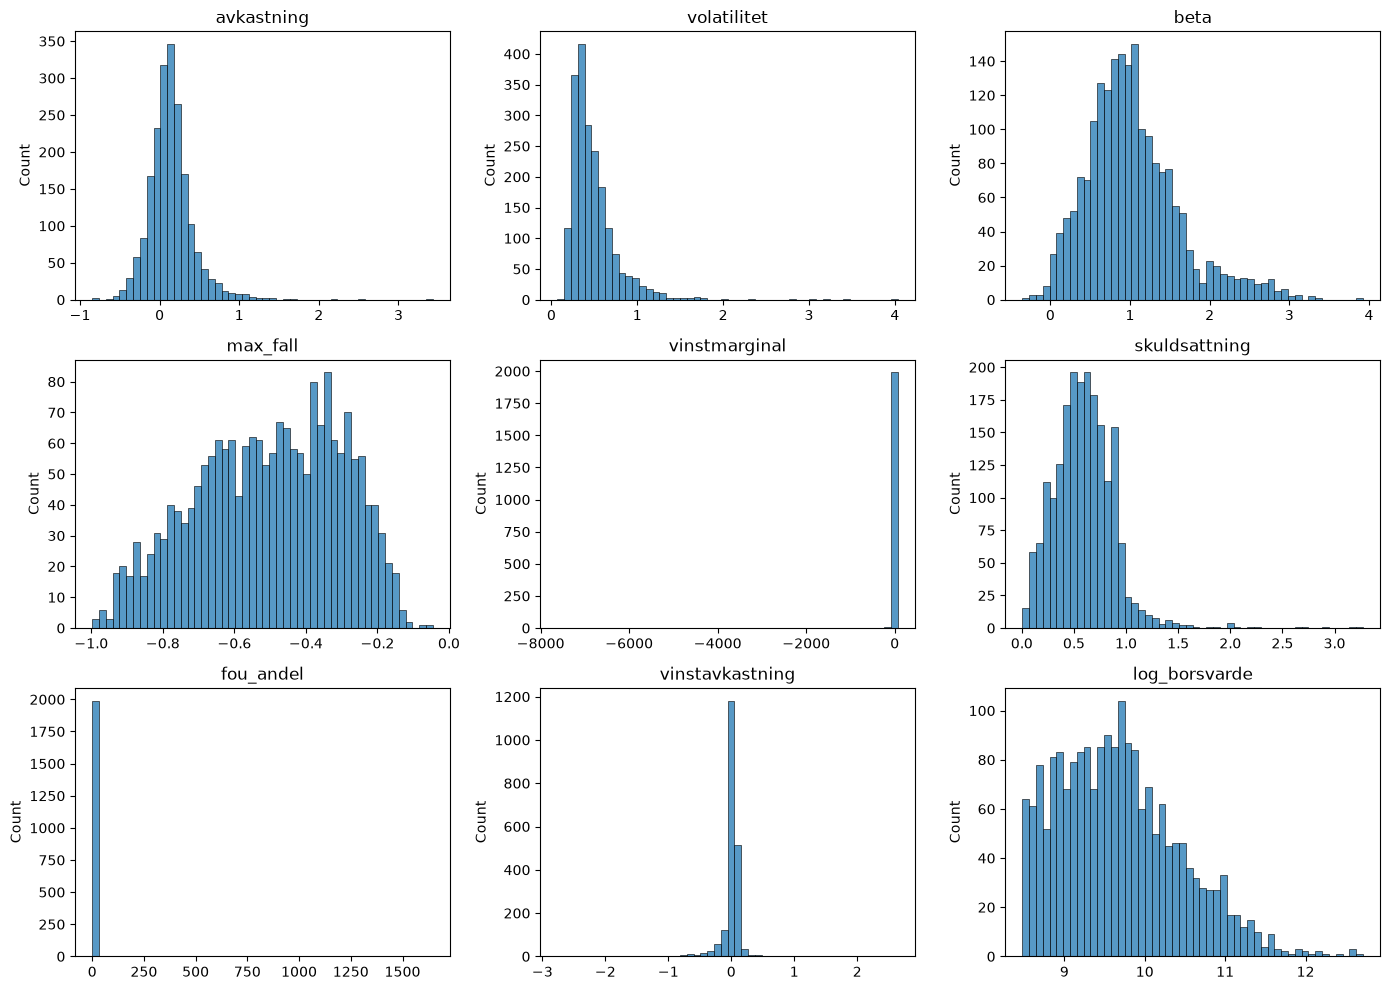

Skevhet per nyckeltal:
avkastning          2.01
volatilitet         3.85
beta                0.93
max_fall           -0.25
vinstmarginal     -36.15
skuldsattning       1.82
fou_andel          30.30
vinstavkastning    -3.14
log_borsvarde       0.63
dtype: float64


In [8]:
# Ett histogram per nyckeltal i ett rutnät med 3 x 3 diagram
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

# Skevhet: 0 = symmetrisk, över ±1 = tydligt skev
print("Skevhet per nyckeltal:")
print(df[features].skew().round(2))

**Slutsats:**

| Grupp | Nyckeltal | Skevhet | Vad vi ser |
|---|---|---|---|
| Rimliga fördelningar | max_fall, log_borsvarde, beta | −0,25 till 0,93 | Hyfsat symmetriskt och inga extremvärden som sticker ut |
| Skeva | skuldsattning, avkastning, vinstavkastning, volatilitet | 1,8 till 3,9 (i absolut tal) | De flesta aktier har liknande värden, men några få avviker kraftigt och bildar en lång svans |
| Extremt skeva | fou_andel, vinstmarginal | 30 och −36 | Några få bolag med nästan ingen omsättning drar ut skalan, så alla eller nästan alla hamnar i en eller några få staplar |

Extremvärdena hanteras senare i preprocessingen genom att värden under 1:a och över 99:e percentilen sätts till gränsvärdet. På så sätt behålls alla aktier, men några få extrema bolag kan inte styra klustringen.

### 3.4 Korrelationer

Skapar en korrelationsmatris som visar vilka nyckeltal som hänger ihop. Nyckeltal som är mycket starkt korrelerade mäter nästan samma sak och kan ge den egenskapen dubbel vikt i klustringen. Vi använder Spearman-korrelation, som då gör en rangordning vilket gör att matrisen inte påverkas av extremvärden.

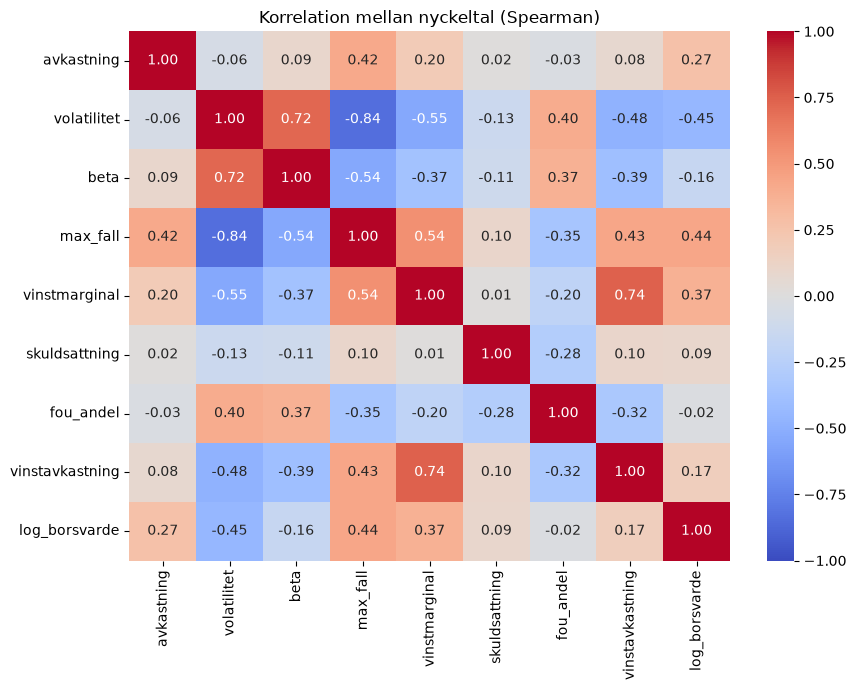

In [9]:
# Spearman-korrelation: jämför aktiernas rangordning i stället för själva värdena
corr = df[features].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korrelation mellan nyckeltal (Spearman)")
plt.tight_layout()
plt.show()

**Slutsats:** Det starkaste sambandet vi kan se är mellan volatilitet och max_fall (största fall) på −0,84: aktier som svänger mycket har också haft de största rasen. Vinstmarginal och vinstavkastning (0,74) mäter båda lönsamhet, och volatilitet och beta (0,72) mäter båda risk, så det är logiska samband.

Genom att titta på vinstmarginal och log_borsvarde och jämföra med volatilitet ser vi att **stora och lönsamma bolag har mindre svängningar**, medan bolag med hög fou_andel (forskningstunga bolag) svänger mer. Skuldsättningen hänger nästan inte ihop med något annat nyckeltal (starkast med FoU-andelen, −0,28) och tillför därför egen information.

Eftersom volatilitet och största fall är så starkt korrelerade (starkare än ±0,8) är det bra att senare testa om klustringen blir bättre om man tar bort max_fall (största fall).

### 3.5 Jämföra olika sektorer

Hur skiljer sig sektorerna åt? Tabellen visar medianvärdet för varje nyckeltal per sektor. Medianen används i stället för medelvärdet eftersom den inte påverkas av extremvärdena. Färgerna gör det lättare att se vilka sektorer som sticker ut i varje kolumn (rött = högt, blått = lågt).

In [10]:
# Medianvärde per sektor, samt antal aktier i varje sektor
sector_summary = (df.groupby("sector")[features].median()
                  .assign(antal=df["sector"].value_counts())
                  .sort_values("volatilitet"))

# Färglägg varje kolumn för sig: rött = högt, blått = lågt
(sector_summary.style
 .background_gradient(cmap="coolwarm", axis=0, subset=features)
 .format("{:.2f}", subset=features))

,avkastning,volatilitet,beta,max_fall,vinstmarginal,skuldsattning,fou_andel,vinstavkastning,log_borsvarde,antal
sector,,,,,,,,,,
Utilities,0.15,0.24,0.37,-0.25,0.11,0.68,0.00,0.04,10.03,67
Real Estate,0.11,0.26,0.60,-0.30,0.13,0.52,0.00,0.03,9.66,100
Consumer Staples,0.02,0.31,0.28,-0.45,0.04,0.54,0.00,0.04,9.51,55
Finance,0.19,0.33,0.82,-0.34,0.15,0.78,0.00,0.06,9.59,267
Industrials,0.13,0.39,1.12,-0.46,0.06,0.53,0.01,0.03,9.71,283
Consumer Discretionary,0.09,0.40,0.94,-0.49,0.05,0.63,0.00,0.04,9.62,475
Energy,0.06,0.44,0.75,-0.53,0.04,0.48,0.00,0.03,9.58,70
Telecommunications,0.16,0.46,1.02,-0.50,0.05,0.54,0.02,0.02,9.38,23
Miscellaneous,0.03,0.50,1.34,-0.64,0.02,0.71,0.06,0.01,9.15,21


**Slutsats:** Sektorerna skiljer sig tydligt åt. **Utilities** och **Consumer Staples** är de stabilaste sektorerna, med lägst volatilitet och beta. Det är stora, stabila bolag som klarar konjunktursvängningar bra, eftersom el och mat behövs i alla lägen. **Technology** och **Health Care** svänger mest och har högst forskningsandel(fou_andel). **Finance** har högst skuldsättning, vilket är väntat eftersom bankernas inlåning räknas som skuld.

Medianen visar dock bara den typiska aktien i varje sektor. Inom en sektor kan aktierna skilja sig mycket åt, och med 2 000 aktier och nio nyckeltal går det inte att överblicka för hand. Det är just detta som klustringen ska undersöka: grupperas aktierna efter sektor, eller finns det andra mönster?

## 4. Statistiskt test

Vi kan inte vara säkra på om skillnaderna mellan sektorerna i tabellen ovan finns på riktigt eller bara beror på slumpen. Det testas med **Kruskal–Wallis-testet**, som jämför alla 12 sektorer.

- **Nollhypotes (H0):** sektorn är "oskyldig" och påverkar inte aktiens nyckeltal. Att t.ex. Utilities har lägre volatilitet än Technology i tabellen är en slump.
- **Mothypotes (H1):** sektorn är "skyldig", alltså påverkar den aktiens nyckeltal. Minst en sektor skiljer sig från de andra.

Kruskal–Wallis väljs i stället för ANOVA eftersom ANOVA förutsätter normalfördelad data, och histogrammen visade att flera nyckeltal är kraftigt skeva. Kruskal–Wallis bygger, liksom Spearman, på rangordning och påverkas därför inte av extremvärden. Signifikansnivån är 0,05.

In [11]:
from scipy.stats import kruskal

results = []
for col in features:
    # En lista med värdena för varje sektor
    groups = [group[col].values for _, group in df.groupby("sector")]
    stat, p = kruskal(*groups)
    results.append({"nyckeltal": col, "H": round(stat, 1), "p-värde": f"{p:.1e}",
                    "signifikant": p < 0.05})

pd.DataFrame(results)

,nyckeltal,H,p-värde,signifikant
0,avkastning,66.5,5.7e-10,True
1,volatilitet,445.0,1.6e-88,True
2,beta,408.2,1.1e-80,True
3,max_fall,362.5,5.3e-71,True
4,vinstmarginal,239.6,4.2e-45,True
5,skuldsattning,203.4,1.5e-37,True
6,fou_andel,777.3,1.4e-159,True
7,vinstavkastning,276.2,8.9e-53,True
8,log_borsvarde,38.6,6.3e-05,True


**Slutsats:** Alla nio nyckeltal visar att sektorerna skiljer sig tydligt åt, och att det inte är slump. Med alla 12 sektorer skulle H i genomsnitt bli cirka 11 om sektorerna vore lika, och gränsen för en signifikant skillnad ligger runt 20. Här ligger H mellan 38,6 och 777,3, alltså långt över. Störst är skillnaden i FoU-andel (H = 777) och volatilitet (445), minst i börsvärde (39).

P-värdet visar att sannolikheten att skillnaderna beror på slump är väldigt låg. P är under 0,05 för alla nyckeltal, vilket är gränsen för signifikans, så skillnaderna är signifikanta.

## 5. Preprocessing

Nyckeltalen räknades fram i avsnitt 3.2. Innan vi genomför klustringen behöver nyckeltalen förberedas i tre steg:

1. **Extremvärden:** några få bolag har extrema värden, som vi såg i histogrammen i 3.3. De begränsas genom att dra en gräns vid 1:a och 99:e percentilen, så att de inte styr klustringen.
2. **Skalning:** nyckeltalen har olika skalor, så vi måste se till att alla har samma typ av skala. Med StandardScaler får alla nyckeltal medelvärde 0 och standardavvikelse 1, så att de väger lika mycket.
3. **PCA:** med PCA kan vi trycka ihop våra 9 nyckeltal till 2 dimensioner för att kunna visualisera aktierna i ett diagram. Själva klustringen görs fortfarande på alla 9 nyckeltal.


### 5.1 Extremvärden

Som vi såg i tabellen efter rensningen (precis innan 3.3) finns några bolag med extrema värden. Ett bolag förlorade t.ex. cirka 7 600 dollar för varje dollar det sålde för (vinstmarginal −7 600), medan hälften av bolagen behåller mellan 0 och 15 cent i vinst per såld dollar (vinstmarginal 0 till 0,15, mellan 25:e och 75:e percentilen). Därför drar vi en gräns vid 1:a och 99:e percentilen, och värden utanför gränsen sätts till gränsvärdet. Detta kallas winsorizing.

Alla aktier behålls och de extrema värdena ligger fortfarande högst och lägst, men inte så långt bort att de styr klustringen.

In [12]:
# Kopia av nyckeltalen som vi döper till x, detta så att originalvärdena finns kvar i df
X = df[features].copy()

# Gränserna: värdet vid 1:a och 99:e percentilen för varje nyckeltal
lower = X.quantile(0.01)
upper = X.quantile(0.99)

# Sätt alla värden utanför gränserna till gränsvärdet
X = X.clip(lower=lower, upper=upper, axis=1)

# Jämför skevheten före och efter
pd.DataFrame({"före": df[features].skew(),
              "efter": X.skew(),
              "gräns 1 %": lower,
              "gräns 99 %": upper}).round(2)

,före,efter,gräns 1 %,gräns 99 %
avkastning,2.01,0.90,-0.42,1.11
volatilitet,3.85,1.54,0.18,1.38
beta,0.93,0.85,0.02,2.80
max_fall,-0.25,-0.24,-0.93,-0.15
vinstmarginal,-36.15,-7.27,-32.62,2.85
skuldsattning,1.82,0.47,0.08,1.48
fou_andel,30.30,7.13,0.00,10.86
vinstavkastning,-3.14,-3.38,-0.74,0.23
log_borsvarde,0.63,0.51,8.50,11.61


**Resultat:** Winsorizingen minskade skevheten kraftigt för flera nyckeltal, t.ex. avkastning, volatilitet och skuldsättning. Däremot är vinstmarginal och FoU-andel fortfarande mycket skeva. Där är fler än 1 % av bolagen extrema, så gränsen hamnar fortfarande på orimliga värden, t.ex. en vinstmarginal på −32 (en förlust på 32 dollar per såld dollar).

För dessa två nyckeltal används i stället ekonomiskt rimliga gränser:
- **Vinstmarginal: −100 % till +100 %.** Ett bolag som förlorar mer än hela sin omsättning är djupt olönsamt, oavsett om förlusten är 2 eller 7 600 gånger omsättningen.
- **FoU-andel: 0 % till 100 %.** Ett bolag som forskar för mer än hela sin omsättning är ett rent forskningsbolag, oavsett hur mycket mer.

In [13]:
# Hur många aktier påverkas av de ekonomiska gränserna?
print(f"Vinstmarginal under −100 %: {(X['vinstmarginal'] < -1).sum()} aktier")
print(f"Vinstmarginal över +100 %:  {(X['vinstmarginal'] > 1).sum()} aktier")
print(f"FoU-andel över 100 %:       {(X['fou_andel'] > 1).sum()} aktier")

# Ekonomiskt rimliga gränser för de två kvoterna som fortfarande är extremt skeva
X["vinstmarginal"] = X["vinstmarginal"].clip(-1, 1)
X["fou_andel"] = X["fou_andel"].clip(0, 1)

print("\nSkevhet efter alla justeringar:")
print(X.skew().round(2))

Vinstmarginal under −100 %: 110 aktier
Vinstmarginal över +100 %:  43 aktier
FoU-andel över 100 %:       76 aktier

Skevhet efter alla justeringar:
avkastning         0.90
volatilitet        1.54
beta               0.85
max_fall          -0.24
vinstmarginal     -1.07
skuldsattning      0.47
fou_andel          3.38
vinstavkastning   -3.38
log_borsvarde      0.51
dtype: float64


**Resultat:** Som vi ser här har 110 bolag en förlust större än omsättningen, 43 en vinst större än omsättningen och 76 forskar för mer än sin omsättning. När vinstmarginalen begränsades till −100 % och +100 % sjönk skevheten från −7,3 till −1,1 (och från −36 innan winsorizingen).

Två nyckeltal är fortfarande något skeva, men av naturliga skäl:

- **FoU-andel (3,4):** över hälften av bolagen forskar inte alls och ligger på exakt 0, medan några forskar mycket. Det är så verkligheten ser ut, och den skillnaden vill vi att klustringen ska fånga.
- **Vinstavkastning (−3,4):** några bolag har gjort förluster som motsvarar en stor del av sitt börsvärde. Det är verkliga värden.

Det viktiga är att inget nyckeltal längre har de extrema skevheterna som fanns innan, då några få bolag låg tusentals gånger längre bort än resten.

### 5.2 Skalning

Nyckeltalen har olika skalor vilket måste justeras för en bra klustring: volatiliteten ligger mellan cirka 0,2 och 1,4, medan börsvärdet (log) ligger mellan 8,5 och 11,6. Klustringen mäter avstånd mellan aktier, så utan skalning skulle nyckeltal med stora siffror väga mer bara på grund av sin enhet. Med StandardScaler räknas varje nyckeltal om så att medelvärdet blir 0 och standardavvikelsen 1. Ett värde på 2 betyder då att aktien ligger två standardavvikelser över genomsnittet, oavsett vilket nyckeltal det är.

In [14]:
from sklearn.preprocessing import StandardScaler

# Skala alla nyckeltal till medelvärde 0 och standardavvikelse 1
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)

# Kontroll: alla nyckeltal ska ha medelvärde på ungefär 0 och standardavvikelse på ungefär 1
X_scaled.describe().round(2)

,avkastning,volatilitet,beta,max_fall,vinstmarginal,skuldsattning,fou_andel,vinstavkastning,log_borsvarde
count,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00,2002.00
mean,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.12,-1.25,-1.76,-2.12,-3.09,-1.91,-0.41,-5.69,-1.58
25%,-0.60,-0.71,-0.67,-0.76,-0.10,-0.68,-0.41,-0.03,-0.79
50%,-0.08,-0.28,-0.14,0.09,0.09,-0.03,-0.41,0.20,-0.08
75%,0.46,0.41,0.52,0.82,0.34,0.64,-0.14,0.39,0.65
max,3.68,3.82,3.05,1.77,2.90,3.32,4.27,1.70,2.62


**Resultat:** Alla nyckeltal har nu medelvärde 0 och standardavvikelse 1, så de väger lika mycket i klustringen. Nästan alla värden ligger inom 4 standardavvikelser, vilket visar att extremvärdena är under kontroll. Om vi inte hade gjort begränsningen i 5.1 hade t.ex. bolaget med en vinstmarginal på −7 600 hamnat cirka 40 standardavvikelser från genomsnittet.

### 5.3 PCA för visualisering

Varje aktie beskrivs av 9 nyckeltal, alltså 9 dimensioner, vilket inte går att rita (vi kan som mest visualisera 3 dimensioner: bredd, höjd och djup). Med PCA (Principal Component Analysis) trycker vi därför ihop de 9 nyckeltalen till 2 nya axlar, så kallade huvudkomponenter. Varje komponent är en blandning av alla 9 nyckeltal, viktad så att den fångar så mycket som möjligt av skillnaderna mellan aktierna. Med de två komponenterna kan vi rita alla aktier i ett vanligt diagram.

PCA används här bara för att visualisera. Klustringen görs på alla våra 9 skalade nyckeltal.

PC1 förklarar 40%, PC2 16%, tillsammans 56% av variationen


,PC1,PC2
avkastning,-0.08,0.72
volatilitet,0.46,0.16
beta,0.35,0.38
max_fall,-0.44,0.17
vinstmarginal,-0.40,-0.00
skuldsattning,-0.09,-0.23
fou_andel,0.32,0.23
vinstavkastning,-0.34,0.25
log_borsvarde,-0.26,0.34


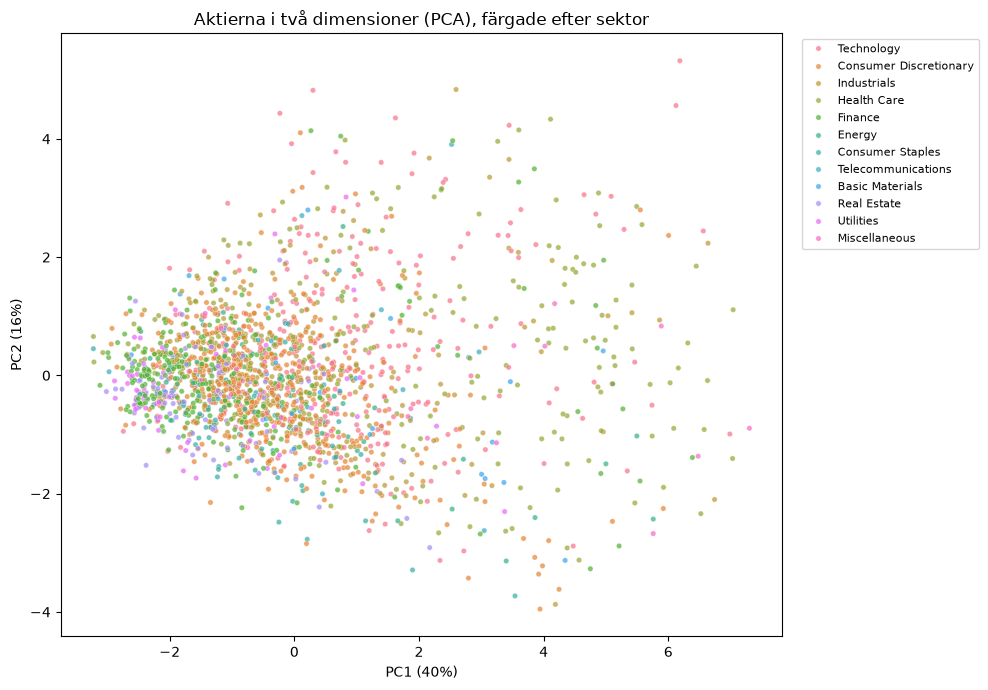

In [15]:
from sklearn.decomposition import PCA

# Tryck ihop de 9 nyckeltalen till 2 huvudkomponenter
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)

# Hur mycket av variationen fångar de två komponenterna?
explained = pca.explained_variance_ratio_
print(f"PC1 förklarar {explained[0]:.0%}, PC2 {explained[1]:.0%}, "
      f"tillsammans {explained.sum():.0%} av variationen")

# Vilka nyckeltal bygger upp varje komponent?
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
display(loadings.round(2))

# Rita alla aktier, färgade efter sektor
plt.figure(figsize=(10, 7))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["sector"], s=15, alpha=0.7)
plt.xlabel(f"PC1 ({explained[0]:.0%})")
plt.ylabel(f"PC2 ({explained[1]:.0%})")
plt.title("Aktierna i två dimensioner (PCA), färgade efter sektor")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Resultat:** De två första komponenterna förklarar tillsammans 56 % av variationen (PC1 40 %, PC2 16 %), så diagrammet visar ungefär hälften av all information.

**PC1-axeln visar risk:** ju längre åt höger, desto mer svängiga, forskningstunga och olönsamma är bolagen, och desto större kursras har de haft. Åt vänster ligger stabila, lönsamma och stora bolag.
**PC2-axeln visar avkastning:** ju högre upp, desto mer har aktien stigit de senaste tre åren.

Sammanfattningsvis ligger de flesta aktier i en tät grupp till vänster (stabila bolag), medan de riskfyllda aktierna sprider ut sig åt höger. Sektorerna överlappar kraftigt: det finns inga tydliga grupper per sektor, även om t.ex. Utilities och Finance främst ligger till vänster och Health Care och Technology sträcker sig längre åt höger. Det tyder på att aktier från olika sektorer ofta liknar varandra, vilket vi med hjälp av vår klustring kommer undersöka närmare.